# Predicción del precio por noche en Airbnb Buenos Aires

**Entrega final: entrenamiento y optimización de modelos de Machine Learning**

Sofia Algamiz · Data Science II · Coderhouse · 2026

## 1. Abstracto con motivación y audiencia

En la primera entrega vimos que el precio de un alquiler temporario en CABA se relaciona con la
ubicación, las comodidades y la reputación del aviso, pero solo con correlaciones sueltas.
Un inversor o un gestor de propiedades no necesita saber únicamente que "el gimnasio suma 29%":
necesita saber **cuánto debería cobrar por una propiedad concreta** y **qué parte de ese precio
depende de cada factor**.

En esta entrega modelamos ese problema. Entrenamos modelos que predicen el precio por noche a partir
de las características del aviso, de su entorno (datos de OpenStreetMap a nivel de cada aviso) y de su
reputación, y los comparamos con validación cruzada. Después usamos el mejor modelo para dos cosas:
explicar qué pesa en el precio (SHAP y ablación por grupos de variables) y detectar avisos publicados
muy por debajo del precio que el mercado sugiere para propiedades parecidas.

**Audiencia.** Inversores inmobiliarios y gestores de alquileres temporarios que quieren fijar o revisar
tarifas con un criterio medible, y el equipo de una plataforma que necesita una referencia de precio por zona.

## 2. Preguntas y problema que buscamos resolver

**Problema principal (regresión):** predecir el precio por noche de un aviso, en pesos argentinos,
usando solo información que el anfitrión conoce al publicar.

Preguntas que guían el trabajo:

1. ¿Qué tan bien se puede predecir el precio y cuánto mejoran los modelos de ensamble frente a un modelo lineal?
2. ¿Cuánto aportan las variables de entorno que armamos con OpenStreetMap (hipótesis 1 de la entrega 1)?
3. ¿Qué tanto depende el modelo de las reseñas (hipótesis 2) y de las comodidades (hipótesis 3)?
4. ¿Qué avisos están publicados muy por debajo de lo que el modelo espera?

**Cómo medimos.** Predecimos `log(precio)` porque el precio tiene una cola derecha muy larga. Elegimos el
modelo con RMSE de validación cruzada y lo informamos también como R², MAE y error relativo en pesos.
Para evitar fugas de información: el conjunto de prueba se separa antes de mirar nada, los límites de
precio y el vocabulario de comodidades salen solo de train, y la imputación y el escalado viven
dentro del `Pipeline`. El test se usa una sola vez, al final.

**Qué agrega respecto de la entrega 1.** Variables por aviso (distancia a estaciones, parques y atracciones, cantidad de
restaurantes cerca) en lugar de un promedio por barrio, 99 indicadores de comodidades, un análisis de faltantes
y un análisis de ensambles con XGBoost y stacking.

## 3. Análisis exploratorio de datos (EDA)

Armamos primero la base de trabajo (carga de datos, población, variable objetivo y partición) y recién después exploramos, solo sobre train.

### 3.1 Carga de datos

Usamos dos fuentes públicas, igual que en la entrega 1:

- **Inside Airbnb**: publicaciones de CABA (scrape del 29/06/2026).
- **OpenStreetMap vía Overpass API**: coordenadas de restaurantes, estaciones, colectivos, atracciones, parques y supermercados.
  La descarga queda guardada en `data/osm_poi_caba.csv`. Para volver a pedirla a la API hay que poner `RUN_OSM = True`.

In [1]:
%pip install -q xgboost shap

In [2]:
import json
import os
import re
import time
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import shap
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, cross_val_predict,
                                     cross_validate, learning_curve, train_test_split)
from sklearn.neighbors import BallTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

SEED = 42
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)

In [3]:
AIRBNB_URL = ("https://data.insideairbnb.com/argentina/ciudad-aut%C3%B3noma-de-buenos-aires/"
              "buenos-aires/2026-06-29/data/listings.csv.gz")
RAW_PATH = "data/dataset_original.csv.gz"

if os.path.exists(RAW_PATH):
    crudo = pd.read_csv(RAW_PATH, compression="gzip", low_memory=False)
else:
    crudo = pd.read_csv(AIRBNB_URL, compression="gzip", low_memory=False)
    crudo.to_csv(RAW_PATH, index=False, compression="gzip")

print(f"Avisos en el archivo: {crudo.shape[0]:,} | columnas: {crudo.shape[1]}")

Avisos en el archivo: 29,685 | columnas: 90


In [4]:
OSM_PATH = "data/osm_poi_caba.csv"
OSM_RAW_URL = "https://raw.githubusercontent.com/sofidemier/DSII-Algamiz/main/data/osm_poi_caba.csv"
RUN_OSM = False   # True para volver a descargar de Overpass (tarda unos minutos y a veces falla por carga del servidor)

OVERPASS = "https://overpass-api.de/api/interpreter"
BBOX = "-34.705,-58.531,-34.526,-58.335"   # sur, oeste, norte, este
CATEGORIAS = {
    "gastronomia": ["node[amenity~'^(restaurant|cafe|bar|fast_food|pub)$']"],
    "subte_tren": ["node[railway=station]", "node[station=subway]", "node[railway=subway_entrance]"],
    "colectivo": ["node[highway=bus_stop]"],
    "atraccion": ["node[tourism~'^(attraction|museum|gallery|viewpoint)$']"],
    "parque": ["way[leisure=park]"],
    "supermercado": ["node[shop=supermarket]"],
}


def descargar_osm():
    filas = []
    for cat, filtros in CATEGORIAS.items():
        consulta = "".join(f"{f}({BBOX});" for f in filtros)
        modo = "out center;" if cat == "parque" else "out skel;"   # los parques son poligonos, pedimos el centro
        q = f"[out:json][timeout:60];({consulta});{modo}"
        for intento in range(3):
            try:
                r = requests.post(OVERPASS, data={"data": q}, timeout=(10, 90),
                                  headers={"User-Agent": "tp-ds2-coderhouse/1.0"})
                r.raise_for_status()
                for e in r.json()["elements"]:
                    lat = e.get("lat") or e.get("center", {}).get("lat")
                    lon = e.get("lon") or e.get("center", {}).get("lon")
                    if lat is not None:
                        filas.append((cat, lat, lon))
                break
            except Exception as err:
                print(f"{cat}, intento {intento + 1}: {str(err)[:70]}")
                time.sleep(8)
        time.sleep(3)   # espaciamos los pedidos para no saturar el servidor publico
    return pd.DataFrame(filas, columns=["categoria", "lat", "lon"]).drop_duplicates()


if RUN_OSM:
    osm = descargar_osm()
    osm.to_csv(OSM_PATH, index=False)
elif os.path.exists(OSM_PATH):
    osm = pd.read_csv(OSM_PATH)
else:
    osm = pd.read_csv(OSM_RAW_URL)
    osm.to_csv(OSM_PATH, index=False)

osm["categoria"].value_counts().rename("puntos de interés").to_frame()

,puntos de interés
categoria,
colectivo,7963
gastronomia,5685
parque,1466
supermercado,822
subte_tren,536
atraccion,253


### 3.2 Población, variable objetivo y partición

La población es la misma de la entrega 1: avisos con precio válido, al menos un huésped y estadía mínima de hasta
30 noches (los alquileres mensuales son otro producto).

Lo primero que hacemos es **separar el 20% de prueba**, estratificado por quintiles de precio. Desde acá todo lo que
aprendemos (límites de precio, vocabulario de comodidades, medianas para imputar) sale solo del 80% de train.
En la entrega 1 recortamos el 1% extremo de precio con los cuantiles de todo el dataset. Ahora los límites se
calculan con train y se aplican a ambos conjuntos, de modo que el modelo se evalúa sobre avisos de precio "típico".

In [5]:
d = crudo.copy()
d["precio"] = pd.to_numeric(d["price"].astype(str).str.replace("$", "", regex=False)
                            .str.replace(",", "", regex=False), errors="coerce")

print(f"Sin precio: {d['precio'].isna().sum():,} avisos ({d['precio'].isna().mean():.1%})")
d = d[d["precio"].notna() & (d["precio"] > 0) & (d["accommodates"] > 0) & (d["minimum_nights"] <= 30)].copy()
print(f"Población de trabajo: {len(d):,} avisos")

estrato = pd.qcut(d["precio"], 5, labels=False)
train, test = train_test_split(d, test_size=0.2, random_state=SEED, stratify=estrato)

lim_inf, lim_sup = train["precio"].quantile([0.01, 0.99])
train = train[train["precio"].between(lim_inf, lim_sup)].copy()
test = test[test["precio"].between(lim_inf, lim_sup)].copy()
print(f"Límites de precio (de train): ${lim_inf:,.0f} a ${lim_sup:,.0f} por noche")
print(f"Train: {len(train):,} | Test: {len(test):,}")

Sin precio: 1,792 avisos (6.0%)
Población de trabajo: 27,625 avisos
Límites de precio (de train): $25,650 a $829,254 por noche
Train: 21,658 | Test: 5,420


Respecto de las correcciones de la preentrega, me fue solicitado ampliar el EDA, con foco en las variables que van al modelo. En seis pasos resolvemos el problema: faltantes, variable objetivo, relación numérica con el precio, variables categóricas, colinealidad y geografía.

### 3.3 Valores faltantes

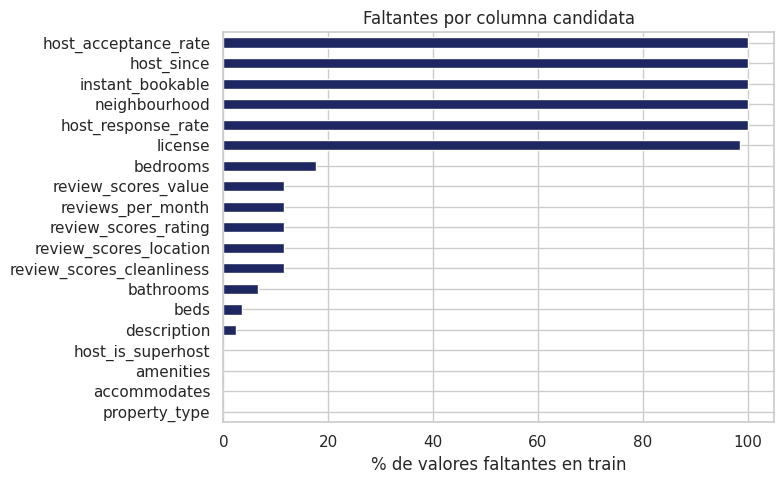

Columnas 100% vacías en este scrape: ['host_acceptance_rate', 'host_since', 'instant_bookable', 'neighbourhood', 'host_response_rate']


In [6]:
candidatas = ["bedrooms", "beds", "bathrooms", "review_scores_rating", "review_scores_location",
              "review_scores_value", "review_scores_cleanliness", "reviews_per_month", "host_is_superhost",
              "instant_bookable", "host_since", "host_response_rate", "host_acceptance_rate", "license",
              "neighbourhood", "description", "amenities", "accommodates", "property_type"]
faltantes = (train[candidatas].isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
faltantes.plot.barh(ax=ax, color="#1E2761")
ax.invert_yaxis()
ax.set_xlabel("% de valores faltantes en train")
ax.set_title("Faltantes por columna candidata")
plt.tight_layout()
plt.show()

print("Columnas 100% vacías en este scrape:", list(faltantes[faltantes == 100].index))

In [7]:
# ¿Los faltantes de reseñas son aleatorios? Miramos qué pasa cuando el aviso no tiene reseñas
sin_res = train["number_of_reviews"] == 0
print(f"Avisos sin reseñas: {sin_res.mean():.1%}")
print(f"Puntaje de reseñas faltante entre los que no tienen reseñas: {train.loc[sin_res, 'review_scores_rating'].isna().mean():.1%}")
print(f"Puntaje de reseñas faltante entre los que sí tienen:        {train.loc[~sin_res, 'review_scores_rating'].isna().mean():.1%}")

# ¿Los faltantes de dormitorios dependen del tipo de alojamiento?
print()
print(train.groupby("room_type")["bedrooms"].agg(avisos="size", pct_faltante=lambda s: round(s.isna().mean() * 100, 1)))

Avisos sin reseñas: 11.5%
Puntaje de reseñas faltante entre los que no tienen reseñas: 100.0%
Puntaje de reseñas faltante entre los que sí tienen:        0.0%

                 avisos  pct_faltante
room_type                            
Entire home/apt   19663          14.8
Hotel room          112           2.7
Private room       1831          48.8
Shared room          52          34.6


**Decisiones sobre faltantes.**

- `instant_bookable`, `host_since`, `host_response_rate`, `host_acceptance_rate` y `neighbourhood` vienen vacías en este scrape, y `license` está casi vacía.
  Las descartamos (para el barrio usamos `neighbourhood_cleansed`, que está completo). En la entrega 1 `instant_bookable` había quedado en el dataset sin ningún valor, y acá lo corregimos.
- Los puntajes de reseñas faltan exactamente cuando el aviso no tiene reseñas (11,5% de los avisos). Es un faltante estructural, no al azar:
  imputamos con la mediana y además agregamos el indicador `sin_reviews`, para que el modelo distinga un aviso nuevo de uno con puntaje típico.
- `bedrooms`, `beds` y `bathrooms` faltan en una parte de los avisos, y tampoco es al azar: los dormitorios faltan en el 48,8% de las habitaciones privadas y en el 14,8% de los alojamientos enteros. Los imputamos con la mediana **dentro del Pipeline**
  (se calcula en cada fold con los datos de entrenamiento de ese fold) y sumamos un indicador de faltante.

### 3.4 Variable objetivo

count     21658.0
mean     123856.0
std       87941.0
min       25650.0
5%        46258.0
25%       76451.0
50%      101250.0
75%      139392.0
95%      278098.0
max      829244.0

Asimetría de precio: 3.29 | de log(precio): 0.53
% de avisos por encima del límite IQR superior: 7.6%


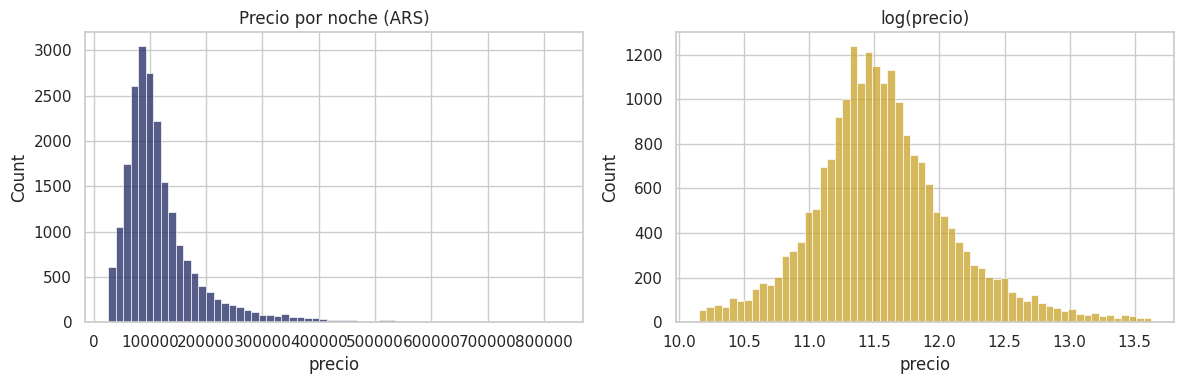

In [8]:
resumen = train["precio"].describe(percentiles=[.05, .25, .5, .75, .95]).round(0)
print(resumen.to_string())
print(f"\nAsimetría de precio: {train['precio'].skew():.2f} | de log(precio): {np.log(train['precio']).skew():.2f}")
q1, q3 = train["precio"].quantile([.25, .75])
print(f"% de avisos por encima del límite IQR superior: {(train['precio'] > q3 + 1.5 * (q3 - q1)).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["precio"], bins=60, ax=ax[0], color="#1E2761")
ax[0].set_title("Precio por noche (ARS)")
sns.histplot(np.log(train["precio"]), bins=60, ax=ax[1], color="#C9A227")
ax[1].set_title("log(precio)")
plt.tight_layout()
plt.show()

El precio mediano es de $101.250 por noche y la media de $123.856: la cola derecha de precios altos tira la media hacia arriba. La asimetría baja de 3,29 a 0,53 al aplicar el logaritmo, y por eso predecimos `log(precio)`. Un 7,6% de los avisos supera el límite superior del rango intercuartil. Los dejamos: ya recortamos el 1% más extremo y los modelos de árboles son poco sensibles a los valores altos.

### 3.5 Variables numéricas contra el precio

Usamos la correlación de Spearman, que mide si la relación es creciente sin exigir que sea lineal.

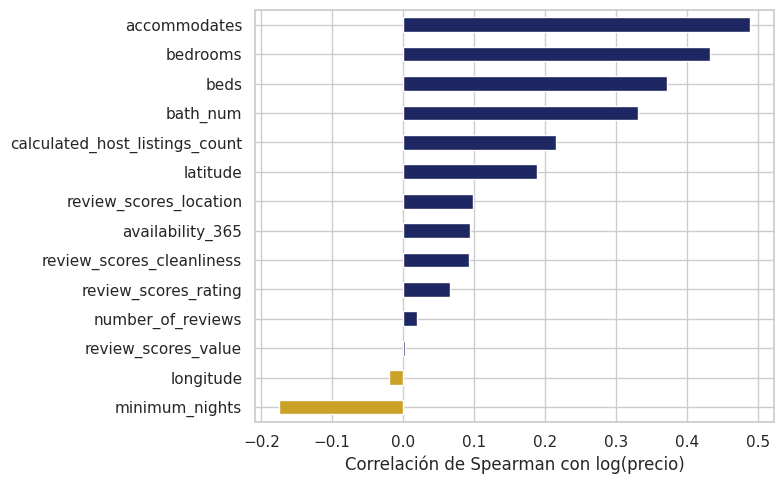

minimum_nights                   -0.18
longitude                        -0.02
review_scores_value               0.00
number_of_reviews                 0.02
review_scores_rating              0.07
review_scores_cleanliness         0.09
availability_365                  0.09
review_scores_location            0.10
latitude                          0.19
calculated_host_listings_count    0.22
bath_num                          0.33
beds                              0.37
bedrooms                          0.43
accommodates                      0.49


In [9]:
train["bath_num"] = pd.to_numeric(train["bathrooms"], errors="coerce")
numericas_raw = ["accommodates", "bedrooms", "beds", "bath_num", "minimum_nights", "availability_365",
                 "number_of_reviews", "review_scores_rating", "review_scores_location", "review_scores_value",
                 "review_scores_cleanliness", "calculated_host_listings_count", "latitude", "longitude"]
rho = train[numericas_raw].apply(lambda s: s.corr(np.log(train["precio"]), method="spearman")).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
rho.plot.barh(ax=ax, color=np.where(rho > 0, "#1E2761", "#C9A227"))
ax.set_xlabel("Correlación de Spearman con log(precio)")
plt.tight_layout()
plt.show()
print(rho.round(2).to_string())

Lo que más se relaciona con el precio es el tamaño: huéspedes (0,49), dormitorios (0,43), camas (0,37) y baños (0,33). Después vienen la cantidad de avisos del anfitrión (0,22) y la latitud (0,19). Las reseñas casi no se asocian con el precio (entre 0,00 y 0,10), lo mismo que ya habíamos visto en la entrega 1. La estadía mínima tiene correlación negativa (-0,18): los avisos que piden más noches cobran menos por noche.

### 3.6 Variables categóricas

Como el precio no es normal, comparamos grupos con Kruskal-Wallis y reportamos el tamaño de efecto (epsilon cuadrado),
porque con tantos avisos casi cualquier diferencia da un p-valor diminuto.

In [10]:
def kruskal_con_efecto(df, grupo, valor="precio", min_n=30):
    g = df.groupby(grupo)[valor].filter(lambda s: len(s) >= min_n)
    sub = df.loc[g.index]
    H, p = stats.kruskal(*[x[valor].values for _, x in sub.groupby(grupo)])
    n = len(sub)
    eps2 = H * (n + 1) / (n ** 2 - 1)
    return {"variable": grupo, "grupos": sub[grupo].nunique(), "H": round(H, 0), "p": f"{p:.1e}", "epsilon²": round(eps2, 3)}


pd.DataFrame([kruskal_con_efecto(train, g) for g in ["room_type", "property_type", "neighbourhood_cleansed"]])

,variable,grupos,H,p,epsilon²
0,room_type,4,2128.0,0.0e+00,0.098
1,property_type,16,2258.0,0.0e+00,0.106
2,neighbourhood_cleansed,30,1898.0,0.0e+00,0.089


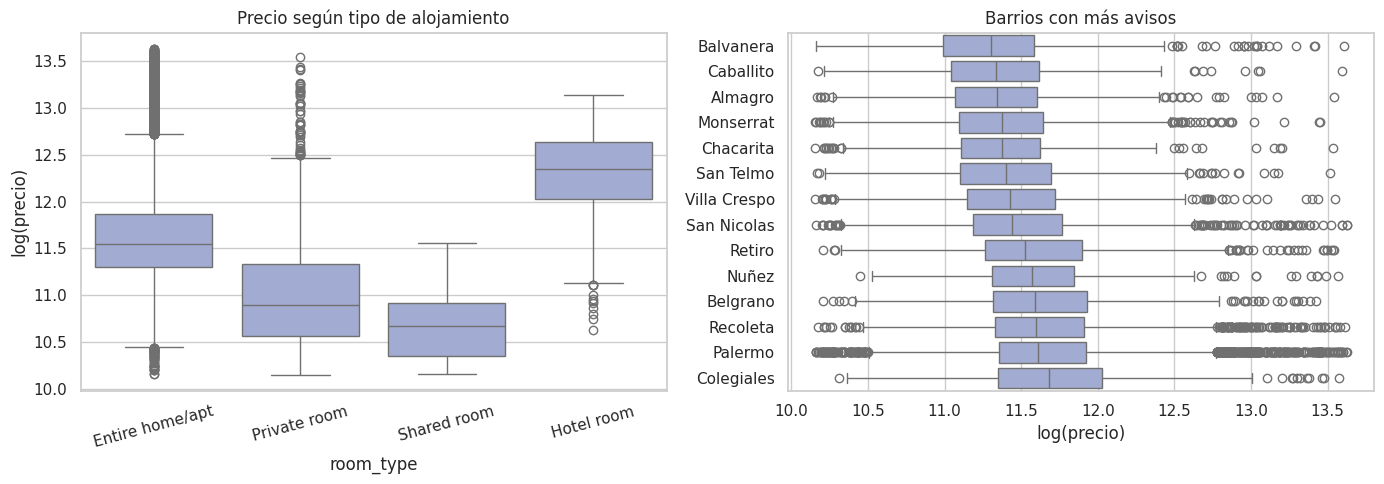

In [11]:
top_barrios = train["neighbourhood_cleansed"].value_counts().head(14).index
orden = (train[train["neighbourhood_cleansed"].isin(top_barrios)]
         .groupby("neighbourhood_cleansed")["precio"].median().sort_values().index)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train, x="room_type", y=np.log(train["precio"]), ax=ax[0], color="#9AA6DA")
ax[0].set_ylabel("log(precio)")
ax[0].set_title("Precio según tipo de alojamiento")
ax[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=train[train["neighbourhood_cleansed"].isin(top_barrios)], y="neighbourhood_cleansed",
            x=np.log(train.loc[train["neighbourhood_cleansed"].isin(top_barrios), "precio"]),
            order=orden, ax=ax[1], color="#9AA6DA")
ax[1].set_xlabel("log(precio)")
ax[1].set_ylabel("")
ax[1].set_title("Barrios con más avisos")
plt.tight_layout()
plt.show()

Los tres tests dan p-valores indistinguibles de cero, como era de esperar con más de 21.000 avisos, por eso miramos el tamaño del efecto: epsilon² de 0,106 para tipo de propiedad, 0,098 para tipo de alojamiento y 0,089 para barrio. Son efectos moderados. El barrio explica alrededor del 9% de la variación en los rangos de precio, bastante menos que el tamaño del aviso.

Los alojamientos tipo hotel tienen la mediana más alta y las habitaciones compartidas la más baja. Entre los 14 barrios con más avisos las medianas van de Balvanera (la más baja) a Colegiales (la más alta), con mucho solapamiento entre las cajas.

### 3.7 Colinealidad

Pares con |rho| >= 0.7:
             level_0                   level_1  rho
review_scores_rating       review_scores_value 0.79
        accommodates                      beds 0.75
review_scores_rating review_scores_cleanliness 0.71


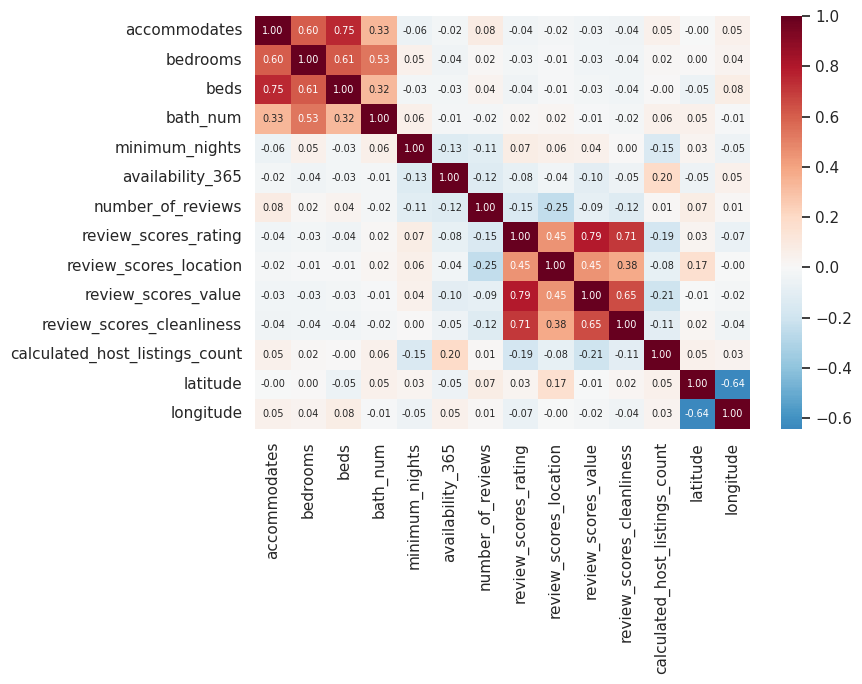

In [12]:
cor = train[numericas_raw].corr(method="spearman")
pares = (cor.where(np.triu(np.ones(cor.shape), k=1).astype(bool)).stack()
            .rename("rho").reset_index().query("abs(rho) >= 0.7").sort_values("rho", ascending=False))
print("Pares con |rho| >= 0.7:")
print(pares.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cor, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
plt.tight_layout()
plt.show()

Hay pocas parejas muy correlacionadas: puntaje general con valor (0,79), huéspedes con camas (0,75) y puntaje general con limpieza (0,71). Es lo esperable, porque los puntajes de reseñas se mueven juntos y las camas dependen de la capacidad. Las dejamos todas: los árboles no se ven afectados y Ridge ya trae regularización, que reparte el peso entre variables parecidas. Lo que sí hacemos es tener cuidado al interpretar la importancia de una variable individual, y por eso en la sección 7.3 usamos también la ablación por grupos.

### 3.8 Geografía

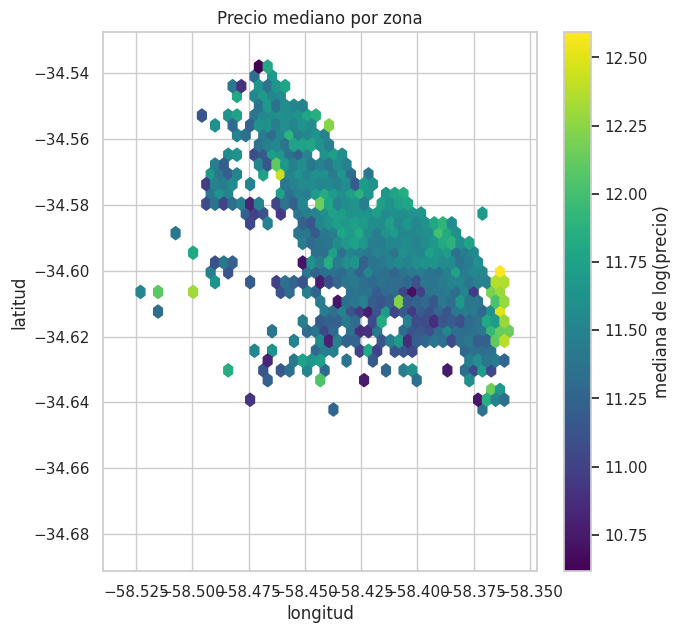

In [13]:
fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(train["longitude"], train["latitude"], C=np.log(train["precio"]), reduce_C_function=np.median,
               gridsize=45, cmap="viridis", mincnt=5)
plt.colorbar(hb, label="mediana de log(precio)")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Precio mediano por zona")
plt.show()

Los precios medianos más altos aparecen sobre el río, en la franja amarilla de Puerto Madero, y en algunos puntos del norte. El resto de la ciudad tiene colores parecidos, sin un gradiente claro desde el centro, y se ven algunas manchas más baratas en el sur y en el oeste.

## 4. Ingeniería de atributos

Armamos cuatro familias de variables nuevas. Todas se calculan fila por fila, o con información externa (OpenStreetMap),
o con un vocabulario aprendido solo de train. Ninguna usa el precio.

1. **Entorno por aviso.** Con un `BallTree` (distancia haversine) calculamos la distancia al Obelisco, a la estación de subte o tren más cercana,
   al parque, a la atracción turística y al supermercado más cercanos, y la cantidad de restaurantes, colectivos, atracciones y supermercados a 500 m
   (y de restaurantes a 1 km). En la entrega 1 esto era un promedio por barrio, ahora cada aviso tiene el suyo.
2. **Capacidad.** Personas por dormitorio, camas por persona y baños por persona.
3. **Comodidades.** Un indicador por cada comodidad presente en entre el 5% y el 95% de los avisos de train, más el total.
4. **Anfitrión y publicación.** Superhost, antigüedad como anfitrión, cantidad de avisos del anfitrión, largo del título y de la descripción.

In [14]:
R_TIERRA = 6371.0   # km


def arbol(cat):
    puntos = np.radians(osm.loc[osm["categoria"] == cat, ["lat", "lon"]].values)
    return BallTree(puntos, metric="haversine")


ARBOLES = {c: arbol(c) for c in osm["categoria"].unique()}
OBELISCO = BallTree(np.radians([[-34.6037, -58.3816]]), metric="haversine")

# el vocabulario de comodidades se aprende solo con train
conteo = Counter(a for lista in train["amenities"].fillna("[]").apply(json.loads) for a in set(lista))
VOCAB = sorted(a for a, c in conteo.items() if 0.05 * len(train) <= c <= 0.95 * len(train))
print(f"Comodidades en el vocabulario: {len(VOCAB)}")


def slug(txt):
    return re.sub(r"[^a-z0-9]+", "_", txt.lower()).strip("_")[:40]


COLS_AM = {a: f"am_{slug(a)}" for a in VOCAB}
assert len(set(COLS_AM.values())) == len(COLS_AM), "nombres de comodidades repetidos"
TIPOS_TOP = list(train["property_type"].value_counts().head(8).index)


def construir_features(df):
    # recibe avisos con las columnas originales de Inside Airbnb y devuelve las variables de modelado
    d = df.copy()
    xy = np.radians(d[["latitude", "longitude"]].values)

    d["dist_centro_km"] = OBELISCO.query(xy, k=1)[0][:, 0] * R_TIERRA
    for cat in ["subte_tren", "parque", "atraccion", "supermercado"]:
        d[f"dist_{cat}_km"] = ARBOLES[cat].query(xy, k=1)[0][:, 0] * R_TIERRA
    for cat in ["gastronomia", "colectivo", "atraccion", "supermercado"]:
        d[f"n_{cat}_500m"] = ARBOLES[cat].query_radius(xy, r=0.5 / R_TIERRA, count_only=True)
    d["n_gastronomia_1km"] = ARBOLES["gastronomia"].query_radius(xy, r=1.0 / R_TIERRA, count_only=True)

    d["bath_num"] = pd.to_numeric(d["bathrooms"], errors="coerce")
    d["pers_por_dorm"] = d["accommodates"] / d["bedrooms"].clip(lower=1)
    d["camas_por_pers"] = d["beds"] / d["accommodates"]
    d["banos_por_pers"] = d["bath_num"] / d["accommodates"]

    lista = d["amenities"].fillna("[]").apply(json.loads)
    d["n_amenities"] = lista.apply(len)
    for a, col in COLS_AM.items():
        d[col] = lista.apply(lambda l, a=a: int(a in l))

    d["superhost"] = (d["host_is_superhost"] == "t").astype(int)
    d["host_years"] = pd.to_numeric(d["hosts_time_as_host_years"], errors="coerce")
    d["sin_reviews"] = (d["number_of_reviews"] == 0).astype(int)
    d["len_nombre"] = d["name"].fillna("").str.len()
    d["len_desc"] = d["description"].fillna("").str.len()
    d["tipo_prop"] = d["property_type"].where(d["property_type"].isin(TIPOS_TOP), "Otro")
    d["log_precio"] = np.log(d["precio"]) if "precio" in d else np.nan
    return d


train_f = construir_features(train)
test_f = construir_features(test)
print(f"Variables disponibles en train: {train_f.shape[1]}")

Comodidades en el vocabulario: 99
Variables disponibles en train: 212


In [15]:
nuevas = ["dist_centro_km", "dist_subte_tren_km", "dist_parque_km", "dist_atraccion_km", "dist_supermercado_km",
          "n_gastronomia_500m", "n_colectivo_500m", "n_atraccion_500m", "n_supermercado_500m", "n_gastronomia_1km",
          "pers_por_dorm", "camas_por_pers", "banos_por_pers", "n_amenities", "len_desc"]
train_f[nuevas].describe().T[["mean", "50%", "min", "max"]].round(2)

,mean,50%,min,max
dist_centro_km,4.02,3.83,0.00,13.98
dist_subte_tren_km,0.41,0.34,0.00,2.62
dist_parque_km,0.23,0.21,0.00,0.85
dist_atraccion_km,0.39,0.31,0.00,2.57
dist_supermercado_km,0.16,0.13,0.00,1.37
n_gastronomia_500m,84.95,82.00,0.00,262.00
n_colectivo_500m,41.80,39.00,0.00,129.00
n_atraccion_500m,3.14,2.00,0.00,21.00
n_supermercado_500m,8.50,8.00,0.00,25.00
n_gastronomia_1km,302.70,328.00,1.00,558.00


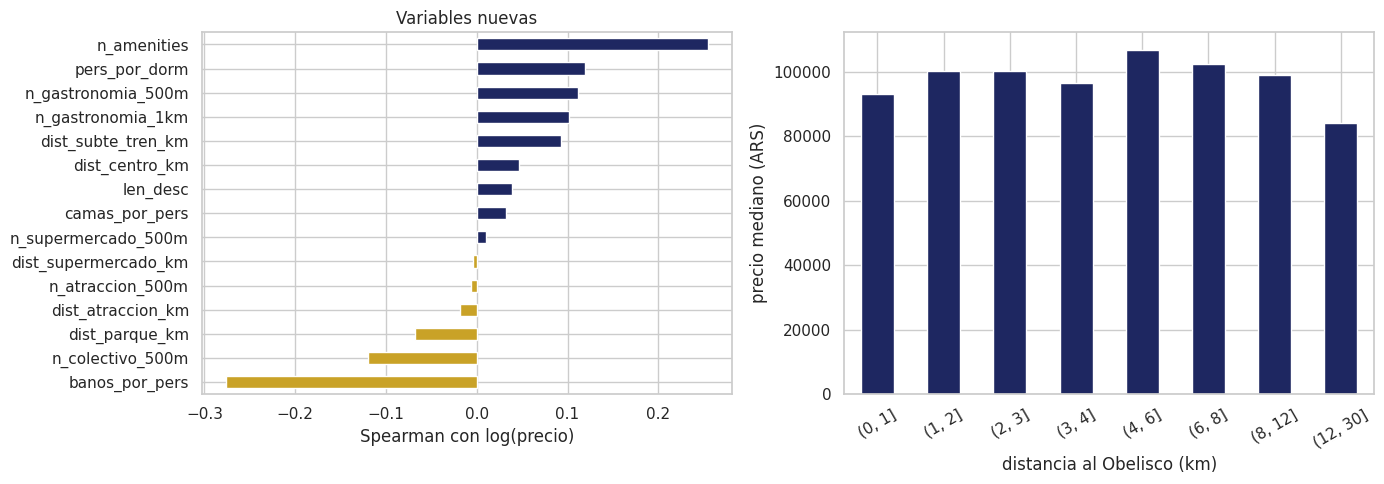

banos_por_pers         -0.28
n_colectivo_500m       -0.12
dist_parque_km         -0.07
dist_atraccion_km      -0.02
n_atraccion_500m       -0.01
dist_supermercado_km   -0.00
n_supermercado_500m     0.01
camas_por_pers          0.03
len_desc                0.04
dist_centro_km          0.05
dist_subte_tren_km      0.09
n_gastronomia_1km       0.10
n_gastronomia_500m      0.11
pers_por_dorm           0.12
n_amenities             0.25

dist_centro_km
(0, 1]       93134.0
(1, 2]      100070.0
(2, 3]      100291.0
(3, 4]       96324.0
(4, 6]      106827.0
(6, 8]      102384.0
(8, 12]      98862.0
(12, 30]     84143.0


In [16]:
rho_nuevas = train_f[nuevas].apply(lambda s: s.corr(train_f["log_precio"], method="spearman")).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rho_nuevas.plot.barh(ax=ax[0], color=np.where(rho_nuevas > 0, "#1E2761", "#C9A227"))
ax[0].set_xlabel("Spearman con log(precio)")
ax[0].set_title("Variables nuevas")

# precio mediano según distancia al Obelisco (tramos de 1 km)
tramos = pd.cut(train_f["dist_centro_km"], bins=[0, 1, 2, 3, 4, 6, 8, 12, 30])
mediana = train_f.groupby(tramos)["precio"].median()
mediana.plot.bar(ax=ax[1], color="#1E2761")
ax[1].set_xlabel("distancia al Obelisco (km)")
ax[1].set_ylabel("precio mediano (ARS)")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print(rho_nuevas.round(2).to_string())
print()
print(mediana.round(0).to_string())

Entre las variables nuevas, las que más se relacionan con el precio son la cantidad de comodidades (0,25), las personas por dormitorio (0,12) y los baños por persona (-0,28, negativa porque los alojamientos chicos tienen más baños por persona). Las de entorno tienen relaciones débiles: restaurantes a 500 m (0,11), distancia a la estación más cercana (0,09) y colectivos cercanos (-0,12).

A la derecha, el precio mediano casi no cambia con la distancia al Obelisco entre 0 y 8 km (de $93.000 a $107.000) y recién baja en la periferia, a más de 12 km ($84.000). La ubicación parece influir menos que el tamaño del alojamiento, algo que la ablación de la sección 7.3 confirma.

### 4.1 Variables excluidas por riesgo de fuga

| Variable | Decisión | Motivo |
|---|---|---|
| `price` | Es el target | Se usa solo como `log(precio)` |
| `estimated_revenue_l365d` | Excluir | Es precio por noches ocupadas, contiene el target |
| `estimated_occupancy_l365d`, `number_of_reviews_ltm`, `reviews_per_month` | Excluir | Se calculan con la actividad reciente, no se conocen al publicar |
| `id`, `host_id`, urls, `picture_url` | Excluir | Identificadores |
| `number_of_reviews`, `review_scores_*` | Incluir y medir su aporte | Son historia del aviso. Un aviso nuevo no las tiene, y lo evaluamos en la ablación de la sección 7.3 |

### 4.2 Preprocesamiento dentro del Pipeline

Armamos grupos de variables para poder probar después qué pasa al sacar cada uno. Las numéricas se imputan con la mediana (con indicador de faltante)
y se estandarizan, y las categóricas se codifican con one-hot, agrupando las categorías con menos de 30 avisos.
Los árboles no necesitan el escalado, pero lo dejamos para que todos los modelos reciban exactamente lo mismo.

In [17]:
GRUPOS = {
    "ubicación": ["latitude", "longitude", "dist_centro_km", "dist_subte_tren_km", "dist_parque_km", "dist_atraccion_km",
                  "dist_supermercado_km", "n_gastronomia_500m", "n_colectivo_500m", "n_atraccion_500m",
                  "n_supermercado_500m", "n_gastronomia_1km"],
    "capacidad": ["accommodates", "bedrooms", "beds", "bath_num", "pers_por_dorm", "camas_por_pers", "banos_por_pers"],
    "reseñas": ["number_of_reviews", "review_scores_rating", "review_scores_location", "review_scores_value",
                "review_scores_cleanliness", "sin_reviews"],
    "comodidades": ["n_amenities"] + list(COLS_AM.values()),
    "anfitrión y aviso": ["superhost", "host_years", "calculated_host_listings_count", "minimum_nights",
                          "availability_365", "len_nombre", "len_desc"],
}
CAT_GRUPOS = {"ubicación": ["neighbourhood_cleansed"], "capacidad": ["room_type", "tipo_prop"]}

NUM = [c for g in GRUPOS.values() for c in g]
CAT = [c for g in CAT_GRUPOS.values() for c in g]
print(f"{len(NUM)} variables numéricas y {len(CAT)} categóricas")


def preprocesador(num=NUM, cat=CAT):
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                          ("escalar", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), cat),
    ], verbose_feature_names_out=False)


def armar(modelo, num=NUM, cat=CAT):
    return Pipeline([("pre", preprocesador(num, cat)), ("modelo", modelo)])


X_train, y_train = train_f[NUM + CAT], train_f["log_precio"]
X_test, y_test = test_f[NUM + CAT], test_f["log_precio"]
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

132 variables numéricas y 3 categóricas


## 5. Entrenamiento y testeo con validación cruzada

Comparamos cinco modelos sobre los mismos 5 folds: un **Dummy** que predice la media (el piso), **Ridge** (lineal con regularización),
**Random Forest** (bagging), **HistGradientBoosting** y **XGBoost** (boosting). Reportamos media ± desvío de RMSE, MAE y R² en validación,
y el R² en entrenamiento para ver cuánto sobreajusta cada uno.

In [18]:
base = {
    "Dummy (media)": DummyRegressor(),
    "Ridge": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                            n_jobs=-1, random_state=SEED),
}
SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}


def evaluar_cv(nombre, pipe, X=X_train, y=y_train):
    t0 = time.time()
    r = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    return {"modelo": nombre,
            "R² val": r["test_r2"].mean(), "R² desvío": r["test_r2"].std(),
            "RMSE val": -r["test_rmse"].mean(), "RMSE desvío": r["test_rmse"].std(),
            "MAE val": -r["test_mae"].mean(), "R² train": r["train_r2"].mean(),
            "seg": time.time() - t0}, r["test_r2"]


filas, r2_folds = [], {}
for nombre, m in base.items():
    fila, folds = evaluar_cv(nombre, armar(m))
    filas.append(fila)
    r2_folds[nombre] = folds
tabla_base = pd.DataFrame(filas).set_index("modelo")
tabla_base.round(3)

,R² val,R² desvío,RMSE val,RMSE desvío,MAE val,R² train,seg
modelo,,,,,,,
Dummy (media),-0.000,0.000,0.536,0.006,0.403,0.000,2.089
Ridge,0.556,0.014,0.357,0.003,0.261,0.565,3.417
Random Forest,0.614,0.014,0.333,0.003,0.239,0.919,197.106
HistGradientBoosting,0.628,0.014,0.327,0.003,0.236,0.734,22.912
XGBoost,0.647,0.013,0.318,0.004,0.228,0.840,35.968


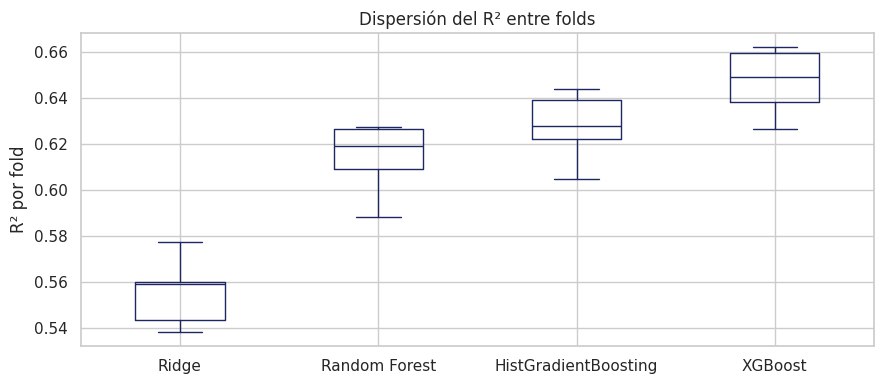

Folds (de 5) en los que XGBoost supera a cada modelo: {'Dummy (media)': 5, 'Ridge': 5, 'Random Forest': 5, 'HistGradientBoosting': 5}


In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame(r2_folds).drop(columns="Dummy (media)").plot.box(ax=ax, color="#1E2761")
ax.set_ylabel("R² por fold")
ax.set_title("Dispersión del R² entre folds")
plt.tight_layout()
plt.show()

gana = {n: int((r2_folds["XGBoost"] > r2_folds[n]).sum()) for n in r2_folds if n != "XGBoost"}
print("Folds (de 5) en los que XGBoost supera a cada modelo:", gana)

XGBoost supera a todos los demás en los cinco folds, con R² de 0,647 y RMSE de 0,318 (en log). El Dummy da 0,536 y Ridge 0,357. Pasar de un modelo lineal a uno de boosting reduce el error un 11%, así que hay relaciones no lineales e interacciones que Ridge no captura. El Random Forest (0,614) queda por debajo de los dos modelos de boosting.

La columna R² train muestra cuánto memoriza cada uno: Random Forest llega a 0,92 y XGBoost a 0,84, contra 0,61 y 0,65 en validación, mientras que Ridge casi no sobreajusta (0,565 contra 0,556).

## 6. Optimización de hiperparámetros

Usamos un método distinto según el modelo, siempre con los mismos folds y RMSE como métrica:

Esta parte es la más lenta del notebook. Con los valores que dejamos tarda unos 10 minutos completo en una computadora de 16 núcleos y bastante más en Colab (calculá una hora). Para una corrida rápida se puede bajar `N_ITER_XGB` y `N_ITER_RF`.

- **Ridge**: `GridSearchCV` sobre `alpha`, porque tiene un solo hiperparámetro.
- **Random Forest** y **XGBoost**: `RandomizedSearchCV`, que muestrea combinaciones al azar dentro de rangos y es más eficiente cuando hay muchos parámetros.

In [20]:
N_ITER_XGB, N_ITER_RF = 15, 5   # combinaciones a probar; con más tiempo se pueden subir

# Ridge
grid_ridge = GridSearchCV(armar(Ridge()), {"modelo__alpha": [0.1, 1, 3, 10, 30, 100, 300]},
                          scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
grid_ridge.fit(X_train, y_train)
print(f"Ridge: alpha={grid_ridge.best_params_['modelo__alpha']}, RMSE CV={-grid_ridge.best_score_:.4f}")

Ridge: alpha=3, RMSE CV=0.3570


In [21]:
# XGBoost
espacio_xgb = {
    "modelo__n_estimators": stats.randint(250, 550),
    "modelo__learning_rate": stats.loguniform(0.03, 0.12),
    "modelo__max_depth": stats.randint(4, 9),
    "modelo__min_child_weight": stats.randint(1, 10),
    "modelo__subsample": stats.uniform(0.6, 0.4),
    "modelo__colsample_bytree": stats.uniform(0.4, 0.5),
    "modelo__reg_lambda": stats.loguniform(0.5, 20),
}
busq_xgb = RandomizedSearchCV(armar(XGBRegressor(n_jobs=1, random_state=SEED)), espacio_xgb, n_iter=N_ITER_XGB,
                              scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, random_state=SEED)
t0 = time.time()
busq_xgb.fit(X_train, y_train)
print(f"XGBoost: {time.time() - t0:.0f} s | RMSE CV={-busq_xgb.best_score_:.4f}")
print({k.replace("modelo__", ""): (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in busq_xgb.best_params_.items()})

XGBoost: 478 s | RMSE CV=0.3149
{'colsample_bytree': 0.4318, 'learning_rate': 0.0462, 'max_depth': 8, 'min_child_weight': 3, 'n_estimators': 421, 'reg_lambda': 5.2526, 'subsample': 0.9549}


In [22]:
# Random Forest
espacio_rf = {
    "modelo__max_depth": [12, 16, 20],
    "modelo__min_samples_leaf": [2, 3, 5],
    "modelo__max_features": [0.3, 0.4, 0.5],
}
busq_rf = RandomizedSearchCV(armar(RandomForestRegressor(n_estimators=100, n_jobs=1, random_state=SEED)), espacio_rf, n_iter=N_ITER_RF,
                             scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, random_state=SEED)
t0 = time.time()
busq_rf.fit(X_train, y_train)
print(f"Random Forest: {time.time() - t0:.0f} s | RMSE CV={-busq_rf.best_score_:.4f}")
print({k.replace("modelo__", ""): v for k, v in busq_rf.best_params_.items()})

Random Forest: 608 s | RMSE CV=0.3330
{'min_samples_leaf': 2, 'max_features': 0.4, 'max_depth': 20}


,RMSE base,RMSE optimizado,mejora %
Ridge,0.3570,0.3570,0.0042
Random Forest,0.3327,0.3330,-0.0774
XGBoost,0.3182,0.3149,1.0317


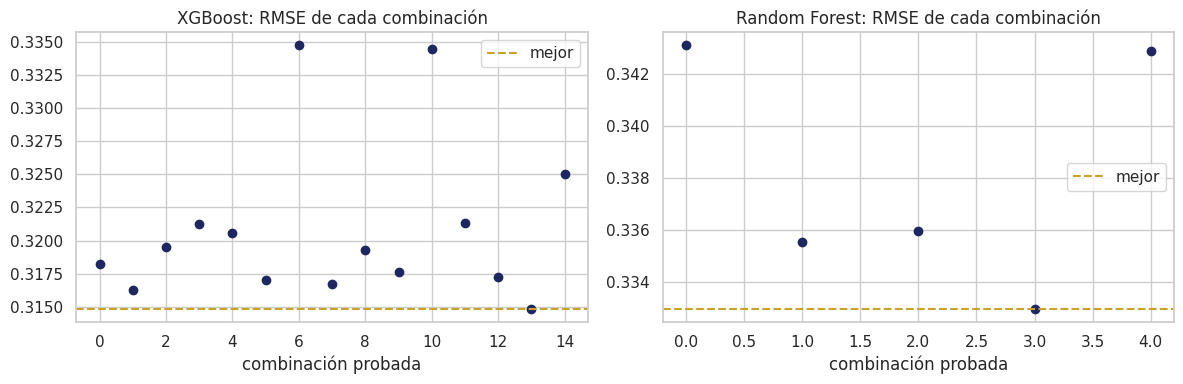

In [23]:
# cuánto mejora el tuning respecto del modelo base, y qué tan dispersas fueron las combinaciones probadas
rmse_base = tabla_base["RMSE val"]
comparacion = pd.DataFrame({
    "RMSE base": [rmse_base["Ridge"], rmse_base["Random Forest"], rmse_base["XGBoost"]],
    "RMSE optimizado": [-grid_ridge.best_score_, -busq_rf.best_score_, -busq_xgb.best_score_],
}, index=["Ridge", "Random Forest", "XGBoost"])
comparacion["mejora %"] = (1 - comparacion["RMSE optimizado"] / comparacion["RMSE base"]) * 100
display(comparacion.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, busq, nombre in [(ax[0], busq_xgb, "XGBoost"), (ax[1], busq_rf, "Random Forest")]:
    res = pd.DataFrame(busq.cv_results_)
    a.scatter(range(len(res)), -res["mean_test_score"], color="#1E2761")
    a.axhline(-busq.best_score_, color="#C9A227", ls="--", label="mejor")
    a.set_title(f"{nombre}: RMSE de cada combinación")
    a.set_xlabel("combinación probada")
    a.legend()
plt.tight_layout()
plt.show()

La optimización mejora poco. XGBoost baja el RMSE de 0,3182 a 0,3149 (1,0%), el Random Forest queda igual (0,3327 contra 0,3330: en el espacio que probamos no apareció nada mejor que sus valores base) y Ridge casi no cambia con `alpha=3`. Los valores por defecto ya estaban cerca del óptimo.

El gráfico muestra que no da lo mismo cualquier combinación: en XGBoost el RMSE de las 15 combinaciones va de 0,315 a 0,335, así que elegir mal los hiperparámetros sí cuesta.

### 6.1 Curva de aprendizaje

Para el XGBoost optimizado miramos cómo cambia el error de entrenamiento y de validación al aumentar la cantidad de avisos.
Si las dos curvas se acercan y se aplanan, más datos no ayudarían mucho. Si siguen separadas, el modelo todavía sobreajusta.

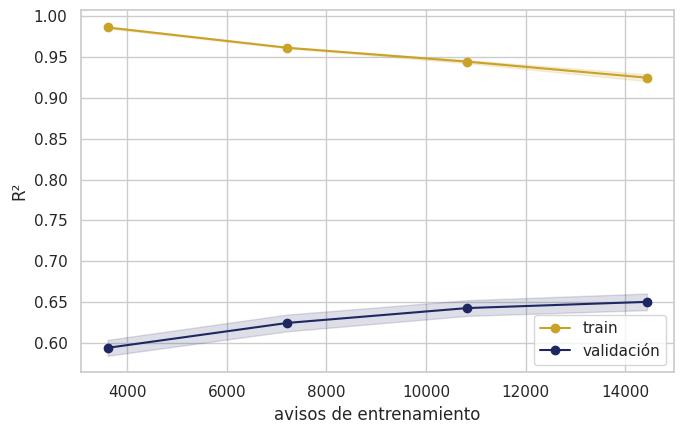

 avisos  R² train  R² validación
   3609     0.986          0.594
   7219     0.961          0.624
  10828     0.944          0.643
  14438     0.925          0.650


In [24]:
xgb_opt = busq_xgb.best_estimator_
tamanos, tr_sc, va_sc = learning_curve(xgb_opt, X_train, y_train, cv=KFold(3, shuffle=True, random_state=SEED),
                                       train_sizes=[0.25, 0.5, 0.75, 1.0], scoring="r2", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for sc, color, et in [(tr_sc, "#C9A227", "train"), (va_sc, "#1E2761", "validación")]:
    ax.plot(tamanos, sc.mean(axis=1), "o-", color=color, label=et)
    ax.fill_between(tamanos, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=0.15)
ax.set_xlabel("avisos de entrenamiento")
ax.set_ylabel("R²")
ax.legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame({"avisos": tamanos, "R² train": tr_sc.mean(axis=1), "R² validación": va_sc.mean(axis=1)}).round(3).to_string(index=False))

Con el 25% de los avisos de train el R² de validación es 0,594 y sube a 0,650 con todos. Los saltos son cada vez más chicos (+0,030, +0,019 y +0,007) y la curva casi se aplana. El R² de entrenamiento baja de 0,986 a 0,925. Entre las dos curvas hay una brecha grande que se va cerrando: el modelo sobreajusta, y más avisos ayudarían, aunque cada vez menos. Para controlar ese sobreajuste con los datos que tenemos, la búsqueda ya incluye regularización (`reg_lambda`, `min_child_weight`) y submuestreo de filas y columnas.

### 6.2 Ensamble por stacking

Probamos también un `StackingRegressor`: entrena Ridge, Random Forest y XGBoost (con los hiperparámetros optimizados) y un meta-modelo
Ridge que aprende cuánto confiar en cada uno a partir de sus predicciones fuera de fold (3 folds internos, para que no sea tan lento).

In [25]:
stack = StackingRegressor(
    estimators=[("ridge", clone(grid_ridge.best_estimator_.named_steps["modelo"])),
                ("rf", clone(busq_rf.best_estimator_.named_steps["modelo"]).set_params(n_jobs=1)),
                ("xgb", clone(busq_xgb.best_estimator_.named_steps["modelo"]).set_params(n_jobs=1))],
    final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=-1)

## 7. Selección del modelo y evaluación final

### 7.1 Selección del modelo

Comparamos los cuatro candidatos optimizados sobre los mismos folds. Para elegir aplicamos la regla del desvío estándar:
nos quedamos con el modelo **más simple** cuyo RMSE medio esté dentro de un desvío del mejor, para no pagar complejidad por una ganancia que no se distingue del ruido.

In [26]:
candidatos = {
    "Ridge": grid_ridge.best_estimator_,
    "Random Forest": busq_rf.best_estimator_,
    "XGBoost": busq_xgb.best_estimator_,
    "Stacking": Pipeline([("pre", preprocesador()), ("modelo", stack)]),
}
filas = []
for nombre, pipe in candidatos.items():
    fila, _ = evaluar_cv(nombre, clone(pipe))
    filas.append(fila)
seleccion = pd.DataFrame(filas).set_index("modelo")
display(seleccion.round(4))

orden_complejidad = ["Ridge", "Random Forest", "XGBoost", "Stacking"]   # de menor a mayor complejidad
mejor = seleccion["RMSE val"].idxmin()
umbral = seleccion.loc[mejor, "RMSE val"] + seleccion.loc[mejor, "RMSE desvío"]
elegido = next(n for n in orden_complejidad if seleccion.loc[n, "RMSE val"] <= umbral)
print(f"Mejor RMSE medio: {mejor} | tolerancia (1 desvío): {umbral:.4f} | modelo elegido: {elegido}")

,R² val,R² desvío,RMSE val,RMSE desvío,MAE val,R² train,seg
modelo,,,,,,,
Ridge,0.5558,0.0136,0.3570,0.0033,0.2606,0.5653,5.0738
Random Forest,0.6135,0.0132,0.3330,0.0025,0.2396,0.9004,154.9185
XGBoost,0.6545,0.0120,0.3149,0.0031,0.2246,0.9134,40.1093
Stacking,0.6559,0.0131,0.3142,0.0036,0.2237,0.9001,587.2701


Mejor RMSE medio: Stacking | tolerancia (1 desvío): 0.3178 | modelo elegido: XGBoost


El stacking tiene el mejor RMSE medio (0,3142), pero la diferencia con XGBoost (0,3149) es de 0,0007, unas cinco veces menos que el desvío entre folds (0,0036). Por la regla del desvío estándar nos quedamos con XGBoost, que es un solo modelo y se entrena mucho más rápido. El meta-modelo del stacking le da 0,92 de peso a XGBoost, 0,10 a Ridge y 0,03 al Random Forest: casi todo lo que aporta el ensamble ya está en XGBoost.

In [27]:
modelo_final = clone(candidatos[elegido])
modelo_final.fit(X_train, y_train)

# pesos que el stacking le da a cada modelo base (solo informativo)
stack_info = clone(candidatos["Stacking"]).fit(X_train, y_train).named_steps["modelo"]
print("Pesos del meta-modelo:", dict(zip(["ridge", "rf", "xgb"], stack_info.final_estimator_.coef_.round(3))))

Pesos del meta-modelo: {'ridge': np.float64(0.104), 'rf': np.float64(0.033), 'xgb': np.float64(0.918)}


### 7.2 Evaluación final en test (una sola vez)

El conjunto de prueba se usó recién ahora y no cambió ninguna decisión anterior. Mostramos las métricas en escala logarítmica y
en pesos. Un error relativo del 20% significa, por ejemplo, equivocarse por $20.000 en un aviso de $100.000.

In [28]:
def metricas(y_log, pred_log):
    real, pred = np.exp(y_log), np.exp(pred_log)
    err_rel = np.abs(pred - real) / real
    return {"R²": 1 - np.sum((y_log - pred_log) ** 2) / np.sum((y_log - y_log.mean()) ** 2),
            "RMSE (log)": np.sqrt(np.mean((y_log - pred_log) ** 2)),
            "MAE (ARS)": np.mean(np.abs(pred - real)),
            "error relativo mediano": err_rel.median() if hasattr(err_rel, "median") else np.median(err_rel),
            "% dentro de ±20%": np.mean(err_rel <= 0.20) * 100}


pred_test = modelo_final.predict(X_test)
referencias = {"Dummy (media)": armar(DummyRegressor()).fit(X_train, y_train),
               "Ridge base": armar(Ridge(alpha=10)).fit(X_train, y_train)}

tabla_test = pd.DataFrame({elegido + " (final)": metricas(y_test.values, pred_test),
                           **{n: metricas(y_test.values, m.predict(X_test)) for n, m in referencias.items()}}).T
display(tabla_test.round(3))

,R²,RMSE (log),MAE (ARS),error relativo mediano,% dentro de ±20%
XGBoost (final),0.659,0.313,29925.228,0.172,56.384
Dummy (media),-0.000,0.537,50871.232,0.307,33.782
Ridge base,0.549,0.361,35426.081,0.207,48.727


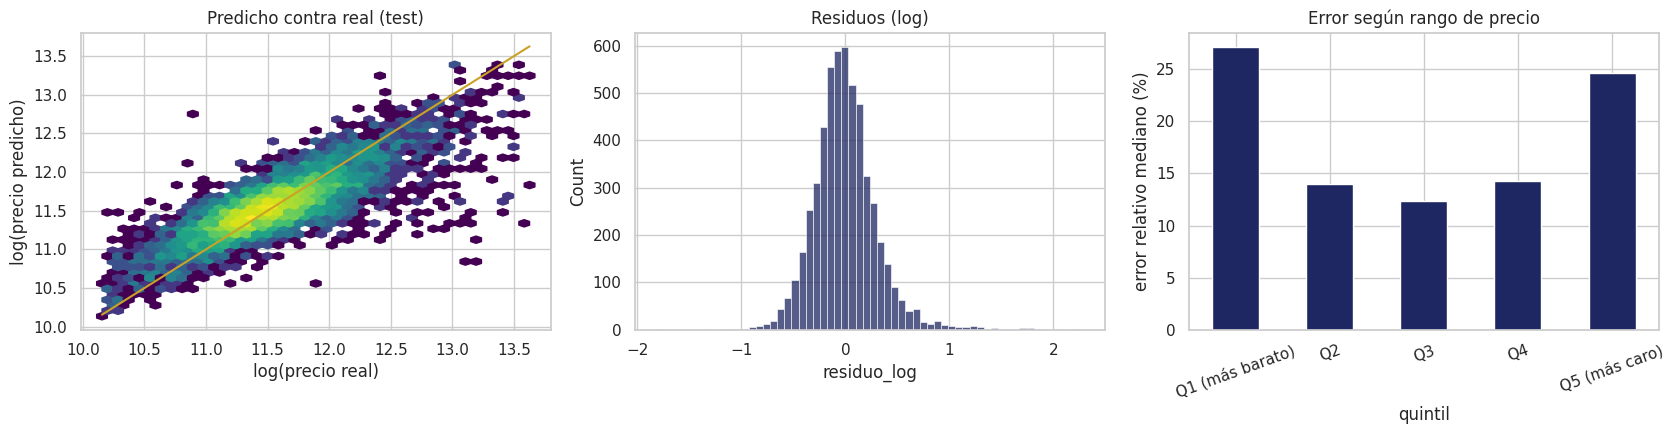

quintil
Q1 (más barato)    27.1
Q2                 13.9
Q3                 12.4
Q4                 14.3
Q5 (más caro)      24.7


In [29]:
real = np.exp(y_test.values)
pred = np.exp(pred_test)
res = pd.DataFrame({"real": real, "pred": pred, "barrio": test_f["neighbourhood_cleansed"].values,
                    "residuo_log": y_test.values - pred_test})
res["quintil"] = pd.qcut(res["real"], 5, labels=["Q1 (más barato)", "Q2", "Q3", "Q4", "Q5 (más caro)"])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
hb = ax[0].hexbin(np.log(res["real"]), np.log(res["pred"]), gridsize=40, cmap="viridis", mincnt=1, bins="log")
lims = [np.log(res["real"]).min(), np.log(res["real"]).max()]
ax[0].plot(lims, lims, color="#C9A227")
ax[0].set_xlabel("log(precio real)")
ax[0].set_ylabel("log(precio predicho)")
ax[0].set_title("Predicho contra real (test)")

sns.histplot(res["residuo_log"], bins=60, ax=ax[1], color="#1E2761")
ax[1].set_title("Residuos (log)")

err = res.assign(err_rel=np.abs(res["pred"] - res["real"]) / res["real"]).groupby("quintil")["err_rel"].median() * 100
err.plot.bar(ax=ax[2], color="#1E2761")
ax[2].set_ylabel("error relativo mediano (%)")
ax[2].set_title("Error según rango de precio")
ax[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print(err.round(1).to_string())

En test, con avisos que el modelo nunca vio, el R² es 0,659 y el RMSE en log 0,313, casi igual que en validación cruzada (0,65 y 0,315). La selección no sobreajustó al train. En pesos, el modelo se equivoca en promedio por $29.925 por aviso, el error relativo mediano es de 17,2% y el 56,4% de los avisos queda dentro de ±20% del precio real. Como referencia, el Dummy tiene un error relativo mediano de 30,7% y Ridge de 20,7%.

El error no es parejo según el rango de precio. El error relativo mediano es de 27,1% en el quintil más barato y de 24,7% en el más caro, contra 12% a 14% en los tres del medio. El modelo acierta más con los avisos típicos y se equivoca más en los extremos.

In [30]:
# sesgo y error por barrio (barrios con al menos 60 avisos en test)
por_barrio = (res.assign(err_rel=np.abs(res["pred"] - res["real"]) / res["real"], sesgo=res["pred"] / res["real"])
                 .groupby("barrio").agg(avisos=("real", "size"), error_rel_mediano=("err_rel", "median"), sesgo_mediano=("sesgo", "median"))
                 .query("avisos >= 60").sort_values("error_rel_mediano"))
display(pd.concat([por_barrio.head(5), por_barrio.tail(5)]).round(3))

,avisos,error_rel_mediano,sesgo_mediano
barrio,,,
Monserrat,274,0.146,0.994
Caballito,85,0.161,0.938
Palermo,1818,0.166,1.019
Balvanera,210,0.166,1.016
Belgrano,277,0.168,1.059
Retiro,257,0.181,1.047
Colegiales,109,0.183,1.055
Villa Crespo,179,0.184,1.033
San Telmo,133,0.203,0.985


Los barrios más fáciles de predecir tienen un error relativo mediano de 15% a 17% (Monserrat, Caballito, Palermo, Balvanera, Belgrano) y los más difíciles de 18% a 22% (Retiro, Colegiales, Villa Crespo, San Telmo, Constitución). El sesgo mediano, que es el precio predicho sobre el real, está entre 0,94 y 1,06 en todos los barrios de la tabla: el modelo no sobreestima ni subestima de forma sistemática a ninguno.

### 7.3 Qué explica el precio

Respondemos las preguntas 2 y 3 de dos formas. Primero **SHAP**, que reparte cada predicción entre las variables. Después una **ablación por grupos**:
reentrenamos el modelo sacando un grupo entero de variables y miramos cuánto empeora el RMSE en validación cruzada (solo con train). La ablación es más directa
que la importancia individual cuando varias variables dicen lo mismo, como las distancias o las comodidades.

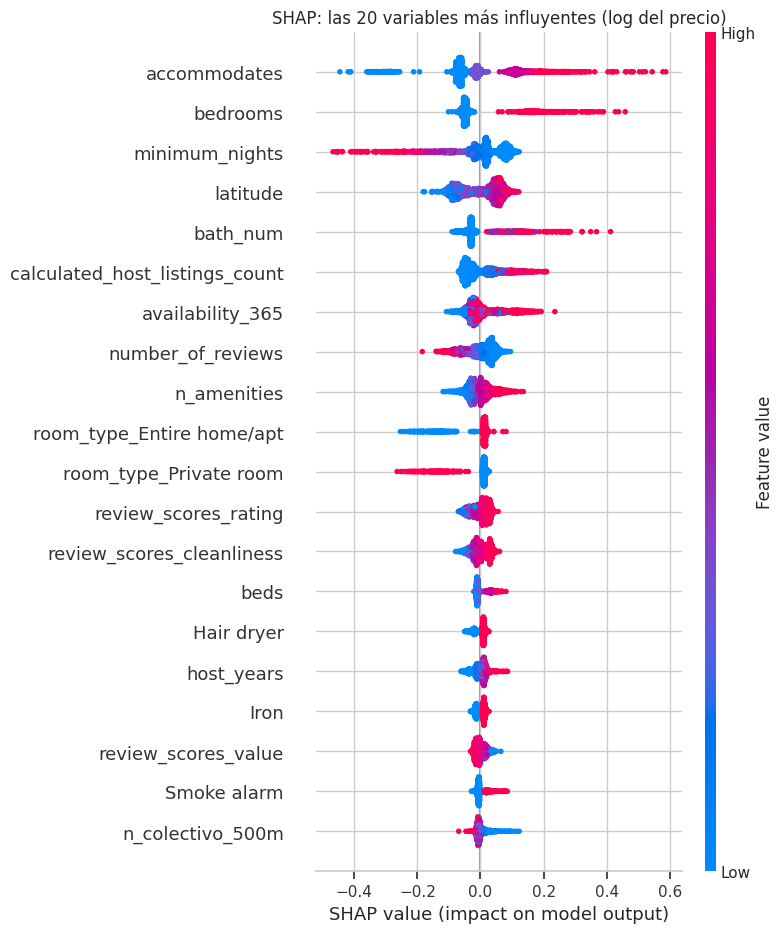

accommodates                      0.091
bedrooms                          0.074
minimum_nights                    0.062
latitude                          0.058
bath_num                          0.052
calculated_host_listings_count    0.047
availability_365                  0.037
number_of_reviews                 0.036
n_amenities                       0.027
room_type_Entire home/apt         0.025
room_type_Private room            0.023
review_scores_rating              0.021
review_scores_cleanliness         0.021
beds                              0.016
Hair dryer                        0.014


In [31]:
modelo_arbol = modelo_final if elegido in ("Random Forest", "XGBoost") else busq_xgb.best_estimator_
pre_fit = modelo_arbol.named_steps["pre"]
nombres = pre_fit.get_feature_names_out()

muestra = X_test.sample(2000, random_state=SEED)
Xm = pre_fit.transform(muestra)
explicador = shap.TreeExplainer(modelo_arbol.named_steps["modelo"])
valores = explicador.shap_values(Xm)

etiquetas = {v: k.replace("_", " ") for k, v in COLS_AM.items()}
leg = [etiquetas.get(n, n) for n in nombres]

shap.summary_plot(valores, Xm, feature_names=leg, max_display=20, show=False)
plt.title("SHAP: las 20 variables más influyentes (log del precio)")
plt.tight_layout()
plt.show()

top_vars = pd.Series(np.abs(valores).mean(axis=0), index=leg).sort_values(ascending=False).head(15)
print(top_vars.round(3).to_string())

Las variables que más mueven la predicción son de tamaño: huéspedes, dormitorios y baños (más grande, más caro). La tercera es la estadía mínima: los avisos que exigen más noches tienen un precio por noche más bajo, lo que sugiere descuentos por estadías largas. La latitud aparece cuarta, con precios más altos hacia el norte de la ciudad. También suben el precio ser un alojamiento entero (contra habitación privada), que el anfitrión tenga más avisos y que haya más días disponibles en el calendario.

Hay un resultado menos intuitivo: a más reseñas, menor precio. Es probable que los avisos que llevan mucho tiempo publicados cobren menos que los nuevos. El puntaje de las reseñas suma, pero poco.

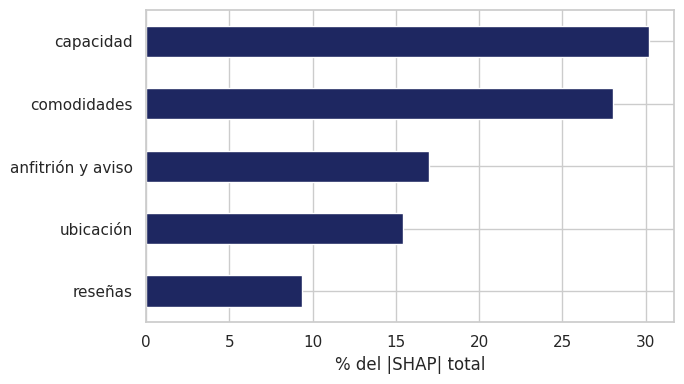

capacidad            30.200001
comodidades          28.000000
anfitrión y aviso    17.000000
ubicación            15.400000
reseñas               9.400000


In [32]:
# SHAP agrupado: qué parte de la predicción se reparte en cada grupo de variables
def grupo_de(nombre):
    base = nombre.replace("missingindicator_", "")
    for g, cols in GRUPOS.items():
        if base in cols:
            return g
    for g, cols in CAT_GRUPOS.items():
        if any(base.startswith(c + "_") for c in cols):
            return g
    return "otros"


importancia = pd.Series(np.abs(valores).mean(axis=0), index=nombres)
por_grupo = importancia.groupby(grupo_de).sum().sort_values()
por_grupo = por_grupo / por_grupo.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4))
por_grupo.plot.barh(ax=ax, color="#1E2761")
ax.set_xlabel("% del |SHAP| total")
plt.tight_layout()
plt.show()
print(por_grupo.round(1).sort_values(ascending=False).to_string())

Si sumamos el SHAP por grupo, capacidad (30,2%) y comodidades (28,0%) quedan parejas, seguidas por anfitrión y aviso (17,0%), ubicación (15,4%) y reseñas (9,4%). Esta suma favorece a los grupos con muchas variables (hay cerca de 100 columnas de comodidades), por eso no sirve para comparar grupos entre sí. La ablación de más abajo mide algo más justo: cuánto empeora el modelo cuando el grupo no está.

In [33]:
# comodidades: efecto que le asigna el modelo (con presente menos ausente) contra el premium simple de la entrega 1
nombre_col = {v: k for k, v in COLS_AM.items()}
filas = []
for i, n in enumerate(nombres):
    if n not in nombre_col:
        continue
    presente = Xm[:, i] > Xm[:, i].min()
    if presente.sum() < 30 or (~presente).sum() < 30:
        continue
    ajustado = valores[presente, i].mean() - valores[~presente, i].mean()
    en_train = train_f[n] == 1
    simple = train_f.loc[en_train, "precio"].mean() / train_f.loc[~en_train, "precio"].mean() - 1
    filas.append({"comodidad": nombre_col[n], "avisos %": en_train.mean() * 100, "premium simple %": simple * 100,
                  "efecto ajustado %": (np.exp(ajustado) - 1) * 100, "|SHAP| medio": np.abs(valores[:, i]).mean()})
comparacion_am = pd.DataFrame(filas)
print("Comodidades con más peso en el modelo:")
display(comparacion_am.sort_values("|SHAP| medio", ascending=False).head(10).round(3).reset_index(drop=True))
clave = comparacion_am[comparacion_am["comodidad"].str.contains("Pool|Air conditioning|parking|gym|Exercise", case=False)]
print("Las que veíamos en la entrega 1 (pileta, aire, cochera, gimnasio):")
display(clave.sort_values("premium simple %", ascending=False).round(1).reset_index(drop=True))

Comodidades con más peso en el modelo:


,comodidad,avisos %,premium simple %,efecto ajustado %,|SHAP| medio
0,Hair dryer,67.970,25.657,3.283,0.014
1,Iron,55.338,25.557,2.662,0.013
2,Smoke alarm,22.181,26.425,3.256,0.011
3,Washer,31.296,13.663,2.225,0.009
4,Self check-in,36.116,17.745,2.032,0.009
5,Private patio or balcony,31.545,13.343,1.995,0.009
6,Pool,12.176,12.967,3.772,0.008
7,Laundromat nearby,36.102,1.762,-1.608,0.008
8,Shared gym in building,7.101,28.506,5.928,0.008
9,Outdoor dining area,24.947,15.051,2.024,0.007


Las que veíamos en la entrega 1 (pileta, aire, cochera, gimnasio):


,comodidad,avisos %,premium simple %,efecto ajustado %,|SHAP| medio
0,Shared gym in building,7.1,28.5,5.9,0.0
1,Exercise equipment,9.4,19.6,4.3,0.0
2,Paid parking on premises,8.6,13.8,1.9,0.0
3,Pool,12.2,13.0,3.8,0.0
4,Paid parking off premises,15.8,8.4,0.0,0.0
5,Free street parking,35.6,6.4,-0.5,0.0
6,Air conditioning,67.3,5.8,1.2,0.0
7,Paid parking lot off premises,13.2,-0.3,0.0,0.0


La tabla compara dos números por comodidad. El premium simple es la diferencia de precio promedio entre los avisos que la tienen y los que no, como hicimos en la entrega 1. El efecto ajustado es lo que el modelo le atribuye a esa comodidad manteniendo igual el resto (tamaño, ubicación, otras comodidades).

La diferencia es grande. El gimnasio compartido pasa de +28,5% a +5,9%, los equipos de ejercicio de +19,6% a +4,3%, la pileta de +13,0% a +3,8% y el aire acondicionado de +5,8% a +1,2%. Buena parte del premium que veíamos en la entrega 1 venía de que esas comodidades están en propiedades más grandes y en edificios con más servicios, no de la comodidad en sí.

Las comodidades más comunes (secador de pelo, plancha, detector de humo) tienen un premium simple de más de 25% y un efecto ajustado de 2,7% a 3,3%. Funcionan como marca de un aviso bien equipado o administrado por un profesional, y no es algo que el huésped pague por separado.

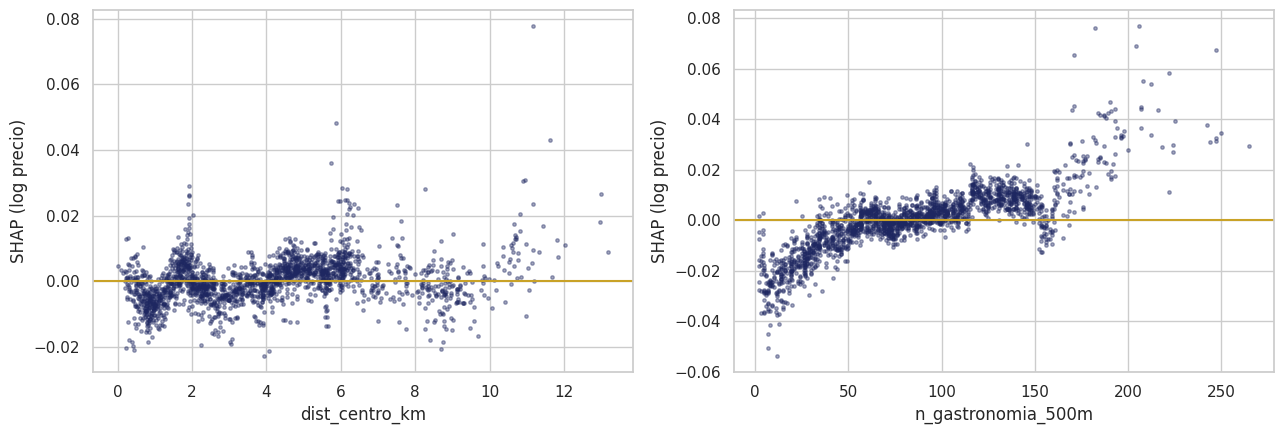

In [34]:
# dependencia de dos variables clave: distancia al centro y restaurantes cercanos
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, var in zip(ax, ["dist_centro_km", "n_gastronomia_500m"]):
    j = list(nombres).index(var)
    a.scatter(muestra[var], valores[:, j], s=6, alpha=0.4, color="#1E2761")
    a.axhline(0, color="#C9A227")
    a.set_xlabel(var)
    a.set_ylabel("SHAP (log precio)")
plt.tight_layout()
plt.show()

In [35]:
# ablación por grupos con los hiperparámetros ya elegidos (solo train, validación cruzada)
modelo_abl = clone(busq_xgb.best_estimator_.named_steps["modelo"]).set_params(n_jobs=-1)
filas = []
completo, _ = evaluar_cv("completo", armar(clone(modelo_abl)))
filas.append({"se saca": "nada (modelo completo)", "RMSE val": completo["RMSE val"], "R² val": completo["R² val"]})
for g in list(GRUPOS):
    num_g = [c for c in NUM if c not in GRUPOS[g]]
    cat_g = [c for c in CAT if c not in CAT_GRUPOS.get(g, [])]
    fila, _ = evaluar_cv(g, armar(clone(modelo_abl), num_g, cat_g))
    filas.append({"se saca": g, "RMSE val": fila["RMSE val"], "R² val": fila["R² val"]})
# ¿las variables de OpenStreetMap aportan algo más allá de las coordenadas y el barrio?
osm_cols = [c for c in GRUPOS["ubicación"] if c.startswith(("dist_", "n_"))]
fila, _ = evaluar_cv("sin OSM", armar(clone(modelo_abl), [c for c in NUM if c not in osm_cols], CAT))
filas.append({"se saca": "solo variables de OpenStreetMap", "RMSE val": fila["RMSE val"], "R² val": fila["R² val"]})
coord = ["latitude", "longitude"]
fila, _ = evaluar_cv("sin coord", armar(clone(modelo_abl), [c for c in NUM if c not in coord], [c for c in CAT if c != "neighbourhood_cleansed"]))
filas.append({"se saca": "solo coordenadas y barrio", "RMSE val": fila["RMSE val"], "R² val": fila["R² val"]})
ablacion = pd.DataFrame(filas).set_index("se saca")
ablacion["pérdida de R²"] = ablacion.loc["nada (modelo completo)", "R² val"] - ablacion["R² val"]
display(ablacion.round(4))

,RMSE val,R² val,pérdida de R²
se saca,,,
nada (modelo completo),0.3149,0.6545,0.0000
ubicación,0.3271,0.6272,0.0272
capacidad,0.4045,0.4302,0.2243
reseñas,0.3193,0.6446,0.0098
comodidades,0.3284,0.6243,0.0302
anfitrión y aviso,0.3411,0.5946,0.0599
solo variables de OpenStreetMap,0.3143,0.6557,-0.0013
solo coordenadas y barrio,0.3172,0.6492,0.0053


Sacar el grupo de capacidad hace caer el R² de 0,65 a 0,43 (una pérdida de 0,22): el tamaño del alojamiento explica por lejos la mayor parte del precio. Después viene anfitrión y aviso (0,060, donde pesan la estadía mínima, la disponibilidad y la cantidad de avisos del anfitrión), comodidades (0,030), ubicación (0,027) y reseñas (0,010).

Sobre la hipótesis 1 de la entrega 1: sacar solo las variables de OpenStreetMap no empeora el resultado (el R² incluso sube 0,001), y sacar solo las coordenadas y el barrio casi tampoco lo cambia (0,005). La pérdida de 0,027 aparece recién cuando se saca todo junto. Es decir que la ubicación importa, pero las coordenadas y las distancias a servicios dicen casi lo mismo y el modelo se arregla con cualquiera de las dos. Una vez que sabemos dónde está el aviso, saber cuántos restaurantes tiene cerca no agrega información.

Sobre la hipótesis 2, las reseñas aportan poco: el modelo sin ninguna variable de reseñas llega a un R² de 0,645, así que también sirve para avisos nuevos.

### 7.4 Caso de uso: precio sugerido contra precio publicado

Para un gestor, el modelo sirve como referencia de tarifa. Calculamos para todos los avisos de la población el precio que el modelo esperaría
(para los de train usamos predicciones fuera de fold, así ningún aviso se predice con un modelo que lo vio) y comparamos con el publicado.
Un aviso por debajo del sugerido puede tener margen para subir la tarifa, aunque el modelo no ve cosas como las fotos o el estado real del departamento.

In [36]:
oof = cross_val_predict(clone(candidatos[elegido]), X_train, y_train, cv=cv, n_jobs=1)
todos = pd.concat([
    train_f.assign(sugerido=np.exp(oof)),
    test_f.assign(sugerido=np.exp(pred_test)),
])
todos["razon"] = todos["precio"] / todos["sugerido"]

print(f"Avisos publicados a menos del 70% del precio sugerido: {(todos['razon'] < 0.7).mean():.1%}")
print(f"Avisos publicados a más del 130% del precio sugerido:  {(todos['razon'] > 1.3).mean():.1%}")

barrios = (todos.groupby("neighbourhood_cleansed")
                .agg(avisos=("precio", "size"), razon_mediana=("razon", "median"),
                     pct_subvaluados=("razon", lambda s: (s < 0.7).mean() * 100))
                .query("avisos >= 150").sort_values("pct_subvaluados", ascending=False))
display(barrios.head(8).round(2))

Avisos publicados a menos del 70% del precio sugerido: 8.9%
Avisos publicados a más del 130% del precio sugerido:  15.1%


,avisos,razon_mediana,pct_subvaluados
neighbourhood_cleansed,,,
Saavedra,152,0.92,15.13
Barracas,195,0.97,12.82
Constitucion,357,0.96,12.61
Villa Urquiza,281,0.98,12.46
Chacarita,453,0.97,11.04
Retiro,1362,0.97,10.21
San Telmo,745,0.98,9.66
Belgrano,1296,0.97,9.65


In [37]:
# tres propiedades de ejemplo, escritas como las publicaría un anfitrión
ejemplos = pd.DataFrame([
    dict(nombre="Dos ambientes en Palermo", latitude=-34.5875, longitude=-58.4300, neighbourhood_cleansed="Palermo",
         room_type="Entire home/apt", property_type="Entire rental unit", accommodates=3, bedrooms=1, beds=2,
         bathrooms=1, minimum_nights=2, availability_365=200, number_of_reviews=25, review_scores_rating=4.8,
         review_scores_location=4.9, review_scores_value=4.7, review_scores_cleanliness=4.8,
         calculated_host_listings_count=1, hosts_time_as_host_years=3, host_is_superhost="f",
         amenities='["Wifi", "Air conditioning", "Kitchen", "Elevator"]', name="Depto luminoso en Palermo", description="x" * 400),
    dict(nombre="Monoambiente en Balvanera", latitude=-34.6090, longitude=-58.4050, neighbourhood_cleansed="Balvanera",
         room_type="Entire home/apt", property_type="Entire rental unit", accommodates=2, bedrooms=1, beds=1,
         bathrooms=1, minimum_nights=1, availability_365=300, number_of_reviews=0, review_scores_rating=np.nan,
         review_scores_location=np.nan, review_scores_value=np.nan, review_scores_cleanliness=np.nan,
         calculated_host_listings_count=4, hosts_time_as_host_years=1, host_is_superhost="f",
         amenities='["Wifi", "Kitchen"]', name="Monoambiente centrico", description="x" * 150),
    dict(nombre="Cuatro ambientes con pileta en Belgrano", latitude=-34.5600, longitude=-58.4560, neighbourhood_cleansed="Belgrano",
         room_type="Entire home/apt", property_type="Entire home", accommodates=7, bedrooms=3, beds=4,
         bathrooms=2, minimum_nights=3, availability_365=120, number_of_reviews=60, review_scores_rating=4.95,
         review_scores_location=4.9, review_scores_value=4.9, review_scores_cleanliness=5.0,
         calculated_host_listings_count=2, hosts_time_as_host_years=6, host_is_superhost="t",
         amenities='["Wifi", "Pool", "Air conditioning", "Kitchen", "Free parking on premises", "Gym"]',
         name="Casa con pileta y parrilla en Belgrano", description="x" * 900),
])
ej_f = construir_features(ejemplos)
ejemplos["precio sugerido por noche (ARS)"] = np.exp(modelo_final.predict(ej_f[NUM + CAT])).round(-2)
ejemplos[["nombre", "accommodates", "precio sugerido por noche (ARS)"]]

,nombre,accommodates,precio sugerido por noche (ARS)
0,Dos ambientes en Palermo,3,85900.0
1,Monoambiente en Balvanera,2,56900.0
2,Cuatro ambientes con pileta en Belgrano,7,194000.0


El 8,9% de los avisos está publicado a menos del 70% del precio sugerido y el 15,1% a más del 130%. Por barrio, Saavedra, Barracas, Constitución y Villa Urquiza tienen la mayor proporción de avisos por debajo del sugerido (entre 12% y 15%).

Para un gestor esto es una lista de avisos para revisar primero, y no una orden de subir precios: el modelo no ve las fotos ni el estado real de la propiedad, y un precio bajo puede ser justamente lo que mantiene la ocupación. Los tres ejemplos de abajo muestran cómo se usa el modelo con una propiedad nueva.

### 7.5 Conclusiones y límites

Predecimos el precio por noche como un problema de regresión sobre `log(precio)`. El modelo elegido, un XGBoost optimizado, llega a un R² de 0,66 en test y a un error relativo mediano de 17%, contra 0,55 y 21% de un Ridge y 31% de una predicción que siempre da la media.

- Los modelos de boosting superan a los lineales y al Random Forest en los cinco folds. El stacking no mejora lo suficiente como para justificar su costo.
- El tamaño del alojamiento explica casi todo el precio. Ubicación, comodidades y reseñas suman cada una entre 1 y 3 puntos de R².
- Hipótesis 1 (entorno): las variables de OpenStreetMap por aviso no agregan información una vez que se conocen las coordenadas.
- Hipótesis 2 (reseñas): aportan poco, y el modelo funciona casi igual sin ellas.
- Hipótesis 3 (comodidades): el premium de la entrega 1 se reduce a una fracción cuando se controla por el resto de las características (por ejemplo, el gimnasio compartido pasa de +28,5% a +5,9%).

Límites de lo que hicimos:

- El precio es el publicado, no el que se cobró. Tampoco tenemos ocupación real: la que trae Inside Airbnb se estima con las reseñas, y por eso no la usamos como objetivo.
- Es una foto de junio de 2026, en pesos y con inflación. Habría que reentrenar el modelo con cada nuevo scrape.
- Evaluamos avisos con precio entre $25.650 y $829.254. Fuera de ese rango no sabemos cómo se comporta.
- Las relaciones que mostramos son asociaciones y no efectos causales. Es una sola ciudad y una sola fecha.

In [38]:
# guardamos las tablas de resultados
pd.concat({"base": tabla_base, "optimizados": seleccion}).to_csv("data/resultados_modelos_tp2.csv")
tabla_test.to_csv("data/metricas_test_tp2.csv")
print("Resultados guardados en data/")

Resultados guardados en data/
